# Algoritmo de Dijkstra (camino más corto)

Idea central: desde un nodo origen, mantener la **distancia más corta conocida** a cada nodo. En cada paso se toma el nodo **no visitado con menor distancia**, se marca como definitivo y se **relajan** sus aristas (si pasar por él mejora la distancia a un vecino, se actualiza).

Solo funciona con **pesos no negativos**.

Comparamos dos formas de elegir "el nodo con menor distancia":

| Versión | Cómo elige el mínimo | Complejidad |
|---|---|---|
| Arreglo (ingenua) | Recorre todos los nodos | $O(V^2)$ |
| Montículo (`heapq`) | Saca el mínimo de un heap | $O((V+E)\log V)$ |

## Versión 1: arreglo (búsqueda lineal del mínimo)

In [1]:
import math

def dijkstra_arreglo(grafo, origen):
    # grafo: {nodo: [(vecino, peso), ...]}
    dist = {v: math.inf for v in grafo}
    previo = {v: None for v in grafo}
    visitado = set()
    dist[origen] = 0

    for _ in range(len(grafo)):
        # Buscar el nodo no visitado con menor distancia: O(V)
        u = None
        for v in grafo:
            if v not in visitado and (u is None or dist[v] < dist[u]):
                u = v

        if u is None or dist[u] == math.inf:
            break  # los nodos restantes son inalcanzables

        visitado.add(u)

        # Relajar las aristas de u
        for v, peso in grafo[u]:
            if dist[u] + peso < dist[v]:
                dist[v] = dist[u] + peso
                previo[v] = u

    return dist, previo

## Versión 2: montículo (`heapq`)

In [2]:
import heapq

def dijkstra_heap(grafo, origen):
    dist = {v: math.inf for v in grafo}
    previo = {v: None for v in grafo}
    dist[origen] = 0
    heap = [(0, origen)]  # (distancia, nodo)

    while heap:
        d, u = heapq.heappop(heap)  # mínimo en O(log V)

        if d > dist[u]:
            continue  # entrada vieja, ya encontramos algo mejor

        for v, peso in grafo[u]:
            if d + peso < dist[v]:
                dist[v] = d + peso
                previo[v] = u
                heapq.heappush(heap, (dist[v], v))

    return dist, previo

## Reconstruir el camino

In [3]:
def camino(previo, destino):
    ruta = []
    while destino is not None:
        ruta.append(destino)
        destino = previo[destino]
    return ruta[::-1]

## Ejemplo

In [4]:
grafo = {
    "A": [("B", 4), ("C", 2)],
    "B": [("C", 5), ("D", 10)],
    "C": [("E", 3)],
    "D": [("F", 11)],
    "E": [("D", 4)],
    "F": [],
}

dist_a, prev_a = dijkstra_arreglo(grafo, "A")
dist_h, prev_h = dijkstra_heap(grafo, "A")

print(f"{'Nodo':<6}{'Arreglo':>9}{'Heap':>7}   Camino")
for v in grafo:
    print(f"{v:<6}{dist_a[v]:>9}{dist_h[v]:>7}   {' -> '.join(camino(prev_h, v))}")

assert dist_a == dist_h
print("\nAmbas versiones dan las mismas distancias.")

Nodo    Arreglo   Heap   Camino
A             0      0   A
B             4      4   A -> B
C             2      2   A -> C
D             9      9   A -> C -> E -> D
E             5      5   A -> C -> E
F            20     20   A -> C -> E -> D -> F

Ambas versiones dan las mismas distancias.


## Generador de grafos aleatorios

`densidad` es la probabilidad de que exista cada arista dirigida:
- densidad baja → grafo **disperso** ($E \approx V$)
- densidad alta → grafo **denso** ($E \approx V^2$)

In [ ]:
import random

def grafo_aleatorio(n, densidad, peso_max=100, semilla=None):
    rnd = random.Random(semilla)
    grafo = {v: [] for v in range(n)}
    for v in range(n - 1):
        grafo[v].append((v + 1, rnd.randint(1, peso_max)))
    for u in range(n):
        for v in range(n):
            if u != v and rnd.random() < densidad:
                grafo[u].append((v, rnd.randint(1, peso_max)))
    return grafo

def num_aristas(grafo):
    return sum(len(adj) for adj in grafo.values())

## Medir tiempos

In [6]:
import time

def medir(funcion, grafo, repeticiones=3):
    mejor = math.inf
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        funcion(grafo, 0)
        mejor = min(mejor, time.perf_counter() - t0)
    return mejor

def comparar(tamanos, densidad_fn):
    filas = []
    for n in tamanos:
        g = grafo_aleatorio(n, densidad_fn(n), semilla=n)
        assert dijkstra_arreglo(g, 0)[0] == dijkstra_heap(g, 0)[0]
        filas.append((n, num_aristas(g), medir(dijkstra_arreglo, g), medir(dijkstra_heap, g)))
    return filas

def imprimir(filas, titulo):
    print(titulo)
    print(f"{'V':>6}{'E':>10}{'Arreglo (ms)':>15}{'Heap (ms)':>12}{'Arreglo/Heap':>15}")
    for n, e, ta, th in filas:
        print(f"{n:>6}{e:>10}{ta*1000:>15.2f}{th*1000:>12.2f}{ta/th:>15.1f}x")

### Grafo disperso (≈ 5 aristas por nodo)

In [7]:
tamanos = [100, 250, 500, 1000, 2000, 3000]
disperso = comparar(tamanos, lambda n: 4 / n)
imprimir(disperso, "Grafo disperso")

Grafo disperso
     V         E   Arreglo (ms)   Heap (ms)   Arreglo/Heap
   100       511           0.60        0.10            5.8x
   250      1230           3.53        0.27           13.0x
   500      2448          14.12        0.62           22.7x
  1000      4925          57.70        1.41           40.8x
  2000     10004         226.80        4.32           52.4x
  3000     15097         535.89        4.57          117.2x


### Grafo denso (≈ 50% de todas las aristas posibles)

In [8]:
denso = comparar(tamanos, lambda n: 0.5)
imprimir(denso, "Grafo denso")

Grafo denso
     V         E   Arreglo (ms)   Heap (ms)   Arreglo/Heap
   100      5075           0.87        0.42            2.0x
   250     31360           5.28        2.07            2.6x
   500    125242          21.15        7.84            2.7x
  1000    501093          86.16       30.10            2.9x
  2000   2001273         347.73      113.07            3.1x
  3000   4503257         766.90      250.50            3.1x


## Gráficas

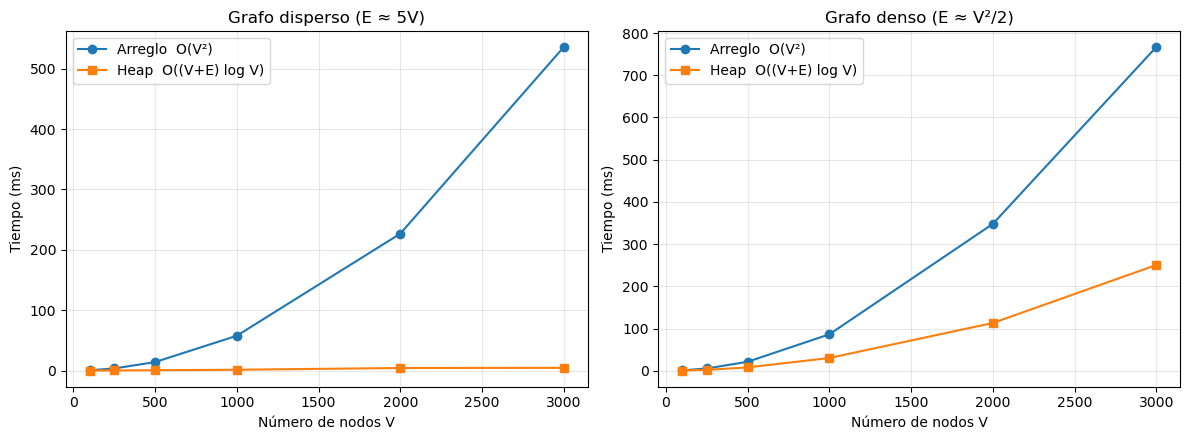

In [9]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, filas, titulo in [(ejes[0], disperso, "Grafo disperso (E ≈ 5V)"),
                          (ejes[1], denso, "Grafo denso (E ≈ V²/2)")]:
    n = [f[0] for f in filas]
    ax.plot(n, [f[2] * 1000 for f in filas], "o-", label="Arreglo  O(V²)")
    ax.plot(n, [f[3] * 1000 for f in filas], "s-", label="Heap  O((V+E) log V)")
    ax.set_title(titulo)
    ax.set_xlabel("Número de nodos V")
    ax.set_ylabel("Tiempo (ms)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## Conclusiones

- Ambas versiones dan **exactamente las mismas distancias**; solo cambia cómo se elige el siguiente nodo.
- En grafos **dispersos** ($E \approx V$) el heap gana por mucho: $O(V \log V)$ contra $O(V^2)$. La ventaja crece con $V$.
- En grafos **densos** ($E \approx V^2$) el heap cuesta $O(V^2 \log V)$ en teoría, peor que $O(V^2)$. En la práctica la ventaja baja de ~100x a ~3x: el trabajo dominante pasa a ser recorrer las aristas, que ambas versiones hacen igual. Que el heap siga ganando se debe a que `heapq` está escrito en C, mientras que la búsqueda lineal del mínimo es un ciclo en Python puro.
- Regla práctica: grafo disperso → heap; grafo muy denso (matriz de adyacencia) → el arreglo es competitivo y más simple, sobre todo en lenguajes compilados donde la búsqueda lineal es barata.
- Ninguna versión sirve con **pesos negativos**; para eso se usa Bellman-Ford.